# WaveGrip: Preprocessing Pipeline 
## GRABMyo: Sample Data Point (Preprocessing Walkthrough)

Tristan Au

This notebook walks through the preprocessing pipeline on one data point (a single trial) of the GRABMyo dataset (PhysioNet v1.1.0) and shows every intermediate step. WFDB (waveform database), SciPY, and pywt (PyWavelets) python libraries are used for processing.  

| Step | Method | Parameters |
|---|---|---|
| 1. Load raw | `wfdb.rdrecord` → physical units (mV) | 12 wrist channels W1–W12, fs = 2048 Hz, 5 s (10240 samples) |
| 2. Filter | the released data is already filtered by the dataset authors | 4th-order Butterworth 10–500 Hz band-pass + 60 Hz notch |
| 3. DWT | `pywt.wavedec` over the whole trial (10240 samples = 5 s, no sliding window) | `db4`, 5 levels, `periodization` → A5, D5…D1 |

**Data point shown:** session 1, participant 1, gesture 16 (Hand Close), trial 1. The DWT views use channel W6.

**Dataset layout:** 3 sessions × 43 participants × 17 gestures × 7 trials = 15,351 trials. Each trial has 32 channels:

- F1–F16: forearm
- W1–W12: wrist
- U1–U4: unused

The goal of this project is to explore if wrist-based sEMG is enough for gesture recognition. Therefore, only the wrist channels are used here.

**Contents**
1. Load the raw data point
2. Check for filtering done by dataset author
3. Discrete Wavelet Transform
   - 3.1 Full-signal DWT and reconstruction analysis
   - 3.2 Comparing discrete wavelet vs. wavelet packet
4. Signal Representation trade-offs: "raw" sEMG vs PSD vs DWT vs WPT 

## 1. Load the raw signal

`wfdb` applies each channel's gain and baseline from the `.hea` header, so `p_signal` is in mV. The wrist channels are interleaved with the unused U channels in the file (…W6, U2, U3, W7…), so they are selected **by name**, not by position.

In [1]:
%matplotlib inline

from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import wfdb

In [ ]:
# ---- Recording selection ----
PROJECT_ROOT = Path.cwd().parent
DATA_ROOT = PROJECT_ROOT / "Dataset" / "physionet.org" / "files" / "grabmyo" / "1.1.0"

SESSION = 1       # 1–3
PARTICIPANT = 1   # 1–43
GESTURE = 16      # 1–17 (see GESTURES below)
TRIAL = 1         # 1–7

GESTURES = [
    "Lateral Prehension", "Thumb Adduction", "Thumb and Little Finger Opposition",
    "Thumb and Index Finger Opposition", "Thumb and Index Finger Extension",
    "Thumb and Little Finger Extension", "Index and Middle Finger Extension",
    "Little Finger Extension", "Index Finger Extension", "Thumb Finger Extension",
    "Wrist Extension", "Wrist Flexion", "Forearm Supination", "Forearm Pronation",
    "Hand Open", "Hand Close", "Rest",
]

In [3]:
def load_grabmyo(session, participant, gesture, trial, root=DATA_ROOT):
    """Read one GRABMyo trial. Returns the wfdb Record (p_signal in mV)."""
    name = f"session{session}_participant{participant}_gesture{gesture}_trial{trial}"
    path = root / f"Session{session}" / f"session{session}_participant{participant}" / name
    return wfdb.rdrecord(str(path))


rec = load_grabmyo(SESSION, PARTICIPANT, GESTURE, TRIAL)
fs = rec.fs

wrist_names = [f"W{i}" for i in range(1, 13)]
wrist_idx = [rec.sig_name.index(n) for n in wrist_names]
wrist = rec.p_signal[:, wrist_idx]            # (n_samples, 12), mV
t = np.arange(rec.sig_len) / fs               # seconds

print(f"Record:   {rec.record_name}")
print(f"Gesture:  {GESTURE} — {GESTURES[GESTURE - 1]}")
print(f"fs = {fs} Hz, {rec.sig_len} samples ({rec.sig_len / fs:.1f} s)")
print(f"Wrist data shape: {wrist.shape}, units: {rec.units[wrist_idx[0]]}")

Record:   session1_participant1_gesture16_trial1
Gesture:  16 — Hand Close
fs = 2048 Hz, 10240 samples (5.0 s)
Wrist data shape: (10240, 12), units: mV


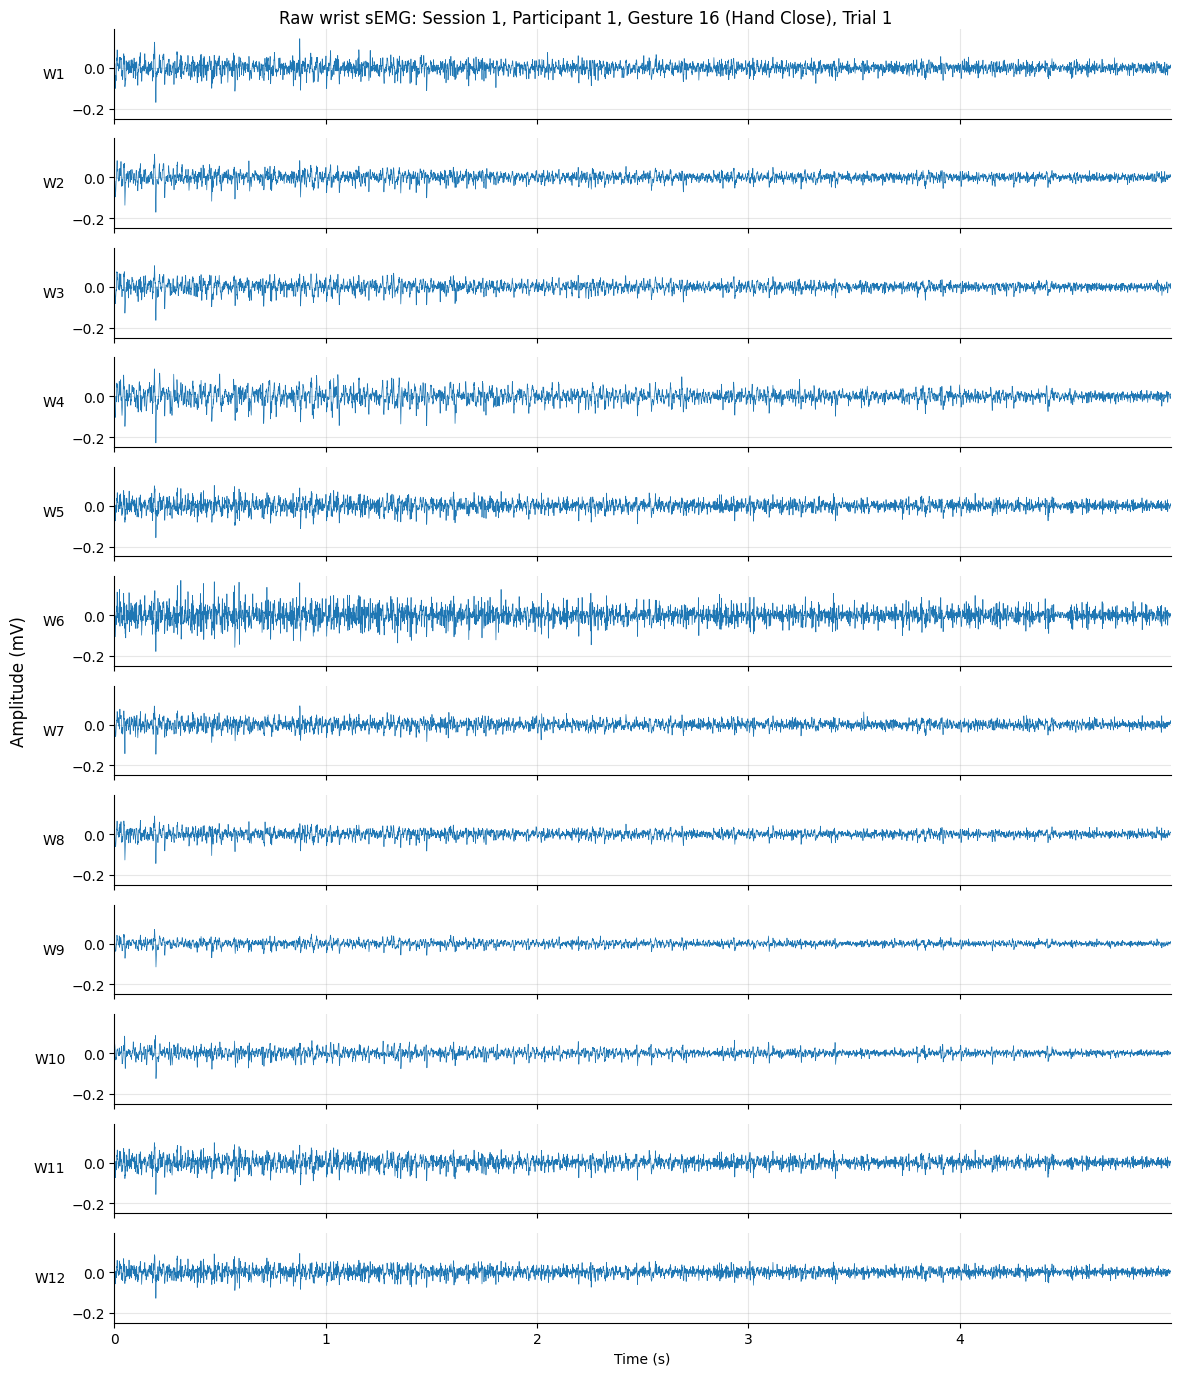

In [4]:
fig, axes = plt.subplots(len(wrist_names), 1, figsize=(12, 14), sharex=True, sharey=True)

for ax, name, ch in zip(axes, wrist_names, wrist.T):
    ax.plot(t, ch, lw=0.5, color="tab:blue")
    ax.set_ylabel(name, rotation=0, ha="right", va="center")
    ax.grid(True, alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)

axes[-1].set_xlabel("Time (s)")
axes[-1].set_xlim(t[0], t[-1])
fig.supylabel("Amplitude (mV)")
fig.suptitle(
    f"Raw wrist sEMG: Session {SESSION}, Participant {PARTICIPANT}, "
    f"Gesture {GESTURE} ({GESTURES[GESTURE - 1]}), Trial {TRIAL}"
)
fig.tight_layout()
plt.show()

## 2. Filtering (already done by dataset authors)

The GRABMyo paper (Pradhan et al., *Scientific Data* 9:733 (2022), Methods › Signal processing) states:

> "The sEMG signals were bandpass filtered between 10 Hz and 500 Hz using a fourth-order Butterworth filter."
>
> "A notch filter of 60 Hz was employed to remove the powerline noise."

The dataset's `grabmyo_convert_wfdb_to_mat.py` also lists `bandpass filtering (hardware) = 10Hz-500Hz`.

Power relative to neighbouring bins, median over the 12 wrist channels:
     60 Hz:  -26.5 dB
    120 Hz:    3.5 dB
    180 Hz:    0.8 dB
    300 Hz:    1.6 dB
Spectrum relative to 100 Hz, median over channels:
      1 Hz:  -38.6 dB
      5 Hz:  -17.4 dB
     10 Hz:   -6.7 dB
    500 Hz:  -18.7 dB
    600 Hz:  -27.2 dB
    800 Hz:  -51.9 dB


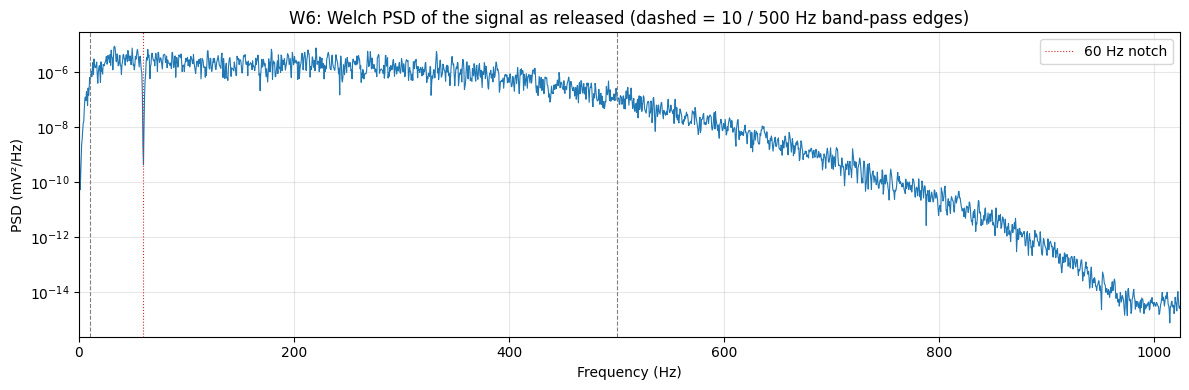

In [ ]:
from scipy import signal

SRC_BP_LOW, SRC_BP_HIGH = 10.0, 500.0   # Hz, 4th-order Butterworth band-pass
SRC_NOTCH = 60.0                        # Hz, power-line notch

CH = "W6"
k = wrist_names.index(CH)
f_w, p_w = signal.welch(wrist, fs=fs, nperseg=4096, axis=0)      # 0.5 Hz bins, shape (n_freq, 12)


def rel_db(f0, p=p_w):
    # Power in the bin at f0 relative to the median of the bins 3-10 Hz away, per channel
    at = np.abs(f_w - f0) <= 0.5
    near = (np.abs(f_w - f0) > 3) & (np.abs(f_w - f0) < 10)
    return 10 * np.log10(p[at].mean(0) / np.median(p[near], axis=0))


print("Power relative to neighbouring bins, median over the 12 wrist channels:")
for f0 in (SRC_NOTCH, 120, 180, 300):
    print(f"  {f0:>5g} Hz: {np.median(rel_db(f0)):6.1f} dB")

ref = np.median(p_w[np.abs(f_w - 100) <= 0.5].mean(0))
print("Spectrum relative to 100 Hz, median over channels:")
for f0 in (1, 5, 10, 500, 600, 800):
    print(f"  {f0:>5g} Hz: {10 * np.log10(np.median(p_w[np.abs(f_w - f0) <= 0.5].mean(0)) / ref):6.1f} dB")

fig, ax = plt.subplots(figsize=(12, 4))
ax.semilogy(f_w, p_w[:, k], color="tab:blue", lw=0.8)
for x_ in (SRC_BP_LOW, SRC_BP_HIGH):
    ax.axvline(x_, color="gray", ls="--", lw=0.8)
ax.axvline(SRC_NOTCH, color="tab:red", ls=":", lw=0.8, label=f"{SRC_NOTCH:g} Hz notch")
ax.set(xlim=(0, fs / 2), xlabel="Frequency (Hz)", ylabel="PSD (mV²/Hz)",
       title=f"{CH}: Welch PSD of the signal as released (dashed = 10 / 500 Hz band-pass edges)")
ax.legend(loc="upper right")
ax.grid(True, which="both", alpha=0.3)
fig.tight_layout()
plt.show()

**Observation**

There is a noticeable loss outside of the frequency band 10-500 Hz, proving that the signal was bandpass filtered.

There is also an outlier at 60 Hz where the GRABMyo authors's claim there was power line interference (PLI), proving the signal was notch filtered.

## 3. Discrete Wavelet Transform

This section looks at one wrist channel in two ways:

1. **Full-signal DWT:** a multi-level decomposition, the sub-band signals rebuilt from each level, and a check that the signal reconstructs perfectly.
2. **Time-frequency tiling:** how the DWT's tiling compares to that of a wavelet packet transform (WPT) at two depths.

`mode="periodization"` makes level *j* produce exactly N/2^j coefficients, so every tile lines up cleanly in time. Its trade-off is some wrap-around at the signal edges.

At fs = 2048 Hz, DWT level *j* covers about fs/2^(j+1) to fs/2^j Hz. For 5 levels:

| Band | Range (Hz) | Coef. spacing |
|---|---|---|
| D1 | 512–1024 | 0.98 ms |
| D2 | 256–512 | 1.95 ms |
| D3 | 128–256 | 3.9 ms |
| D4 | 64–128 | 7.8 ms |
| D5 | 32–64 | 15.6 ms |
| A5 | 0–32 | 15.6 ms |

The 10–500 Hz passband of the released data falls mostly in D2–D5, with its lowest part (10–32 Hz) in A5.

### 3.1 Full-signal DWT
The band energy table and a perfect-reconstruction check, followed by the signal rebuilt from each sub-band on its own.

In [6]:
import pywt

DWT_CH = "W6"          # channel to analyse
WAVELET = "db4"        # mother wavelet (common choice for sEMG)
DWT_LEVEL = 5
DWT_MODE = "periodization"

x = wrist[:, wrist_names.index(DWT_CH)]
N = len(x)

coeffs = pywt.wavedec(x, WAVELET, mode=DWT_MODE, level=DWT_LEVEL)   # [A_L, D_L, ..., D1]
band_names = [f"A{DWT_LEVEL}"] + [f"D{j}" for j in range(DWT_LEVEL, 0, -1)]


def band_range(name, fs=fs):
    j = int(name[1:])
    hi = fs / 2**j
    return (0.0, hi / 2) if name[0] == "A" else (hi / 2, hi)


# Perfect-reconstruction check
x_rec = pywt.waverec(coeffs, WAVELET, mode=DWT_MODE)[:N]
print(f"Channel {DWT_CH}, wavelet {WAVELET}, {DWT_LEVEL} levels "
      f"(max possible for N={N}: {pywt.dwt_max_level(N, pywt.Wavelet(WAVELET).dec_len)})")
print(f"Reconstruction max abs error: {np.max(np.abs(x - x_rec)):.2e} mV\n")

energies = np.array([np.sum(c**2) for c in coeffs])
print(f"{'Band':<5}{'Range (Hz)':>12}{'# coefs':>9}{'Energy %':>10}")
for name, c, e in zip(band_names, coeffs, energies):
    lo, hi = band_range(name)
    print(f"{name:<5}{f'{lo:.0f}-{hi:.0f}':>12}{len(c):>9}{100 * e / energies.sum():>9.1f}%")

Channel W6, wavelet db4, 5 levels (max possible for N=10240: 10)
Reconstruction max abs error: 8.33e-17 mV

Band   Range (Hz)  # coefs  Energy %
A5           0-32      320      5.9%
D5          32-64      320     12.7%
D4         64-128      640     19.9%
D3        128-256     1280     31.8%
D2        256-512     2560     26.7%
D1       512-1024     5120      3.0%


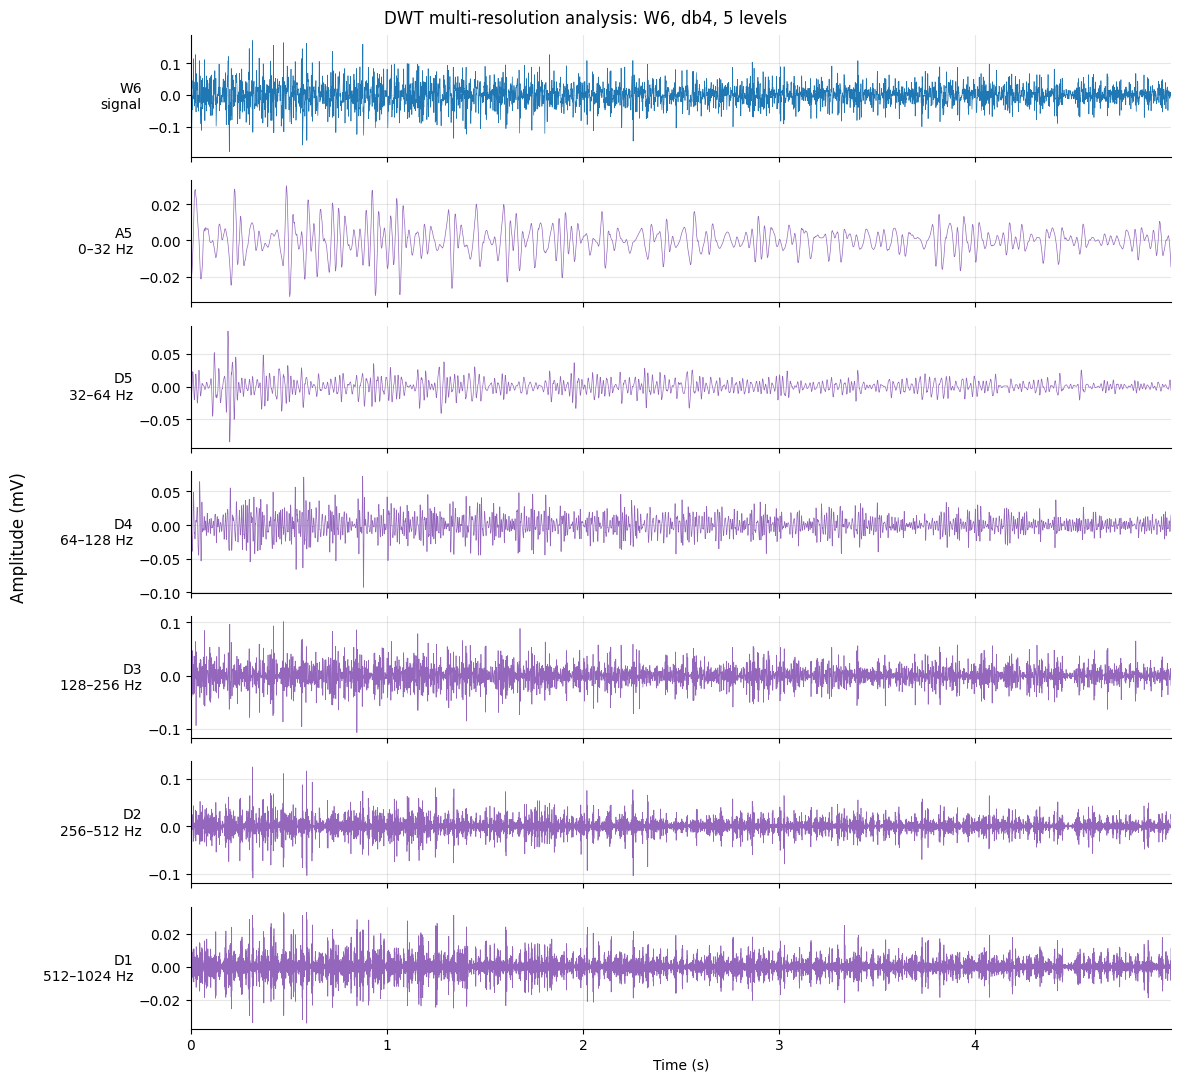

In [7]:
# Multi-resolution analysis: rebuild the signal from each sub-band on its own
def subband_signal(coeffs, keep):
    parts = [c if i == keep else np.zeros_like(c) for i, c in enumerate(coeffs)]
    return pywt.waverec(parts, WAVELET, mode=DWT_MODE)[:N]


fig, axes = plt.subplots(len(coeffs) + 1, 1, figsize=(12, 11), sharex=True)
axes[0].plot(t, x, lw=0.5, color="tab:blue")
axes[0].set_ylabel(f"{DWT_CH}\nsignal", rotation=0, ha="right", va="center")

for ax, i, name in zip(axes[1:], range(len(coeffs)), band_names):
    lo, hi = band_range(name)
    ax.plot(t, subband_signal(coeffs, i), lw=0.5, color="tab:purple")
    ax.set_ylabel(f"{name}\n{lo:.0f}–{hi:.0f} Hz", rotation=0, ha="right", va="center")

for ax in axes:
    ax.grid(True, alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
axes[-1].set_xlabel("Time (s)")
axes[-1].set_xlim(t[0], t[-1])
fig.supylabel("Amplitude (mV)")
fig.suptitle(f"DWT multi-resolution analysis: {DWT_CH}, {WAVELET}, {DWT_LEVEL} levels")
fig.tight_layout()
plt.show()

### 3.2 Time-frequency tiling: DWT vs wavelet packets

Each tile is one coefficient. The DWT splits frequency dyadically (octave bands), while a wavelet packet transform (WPT) at level *L* splits it into 2^L equal bands. Deeper levels trade time resolution for frequency resolution.

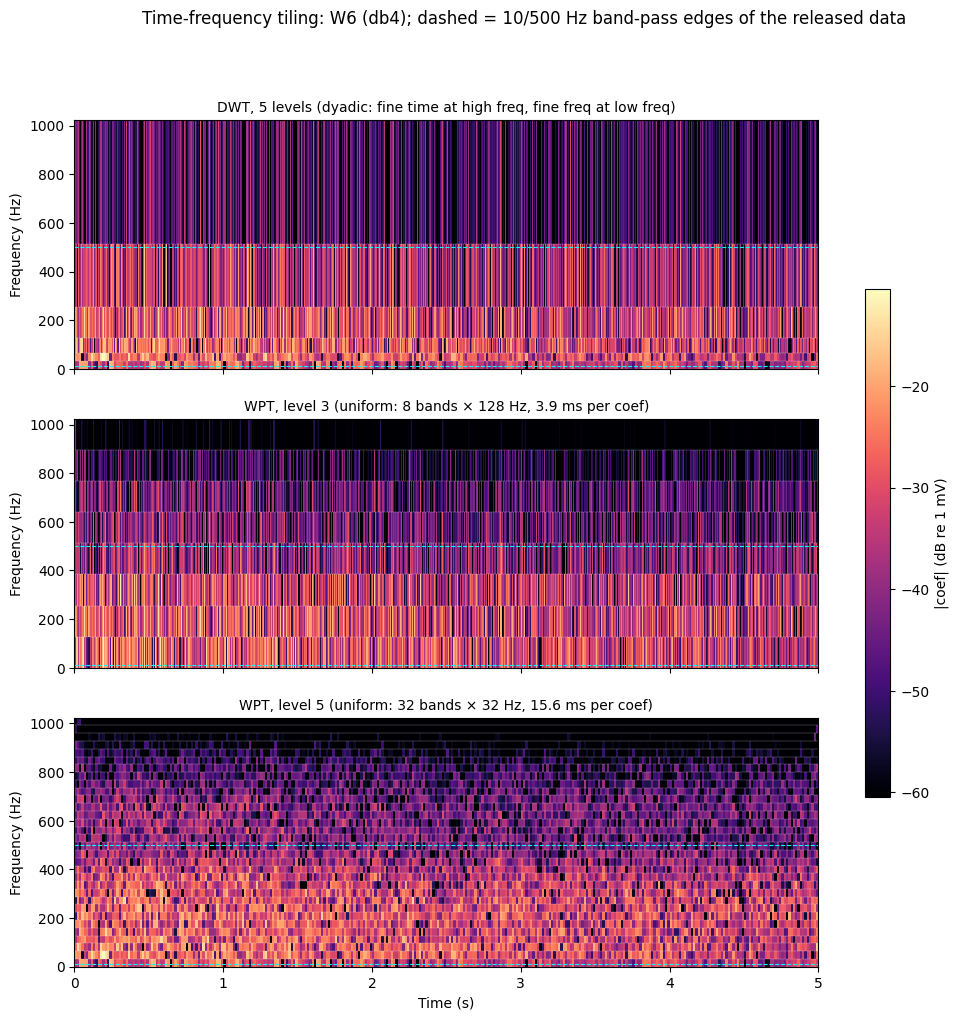

In [8]:
# Time-frequency tiling: dyadic DWT vs uniform wavelet packet (WPT) at two depths.
# Each tile is one coefficient: width = its time support, height = its frequency band,
# colour = coefficient magnitude in dB.
def dwt_tiles(coeffs):
    tiles = []
    for name, c in zip(band_names, coeffs):
        lo, hi = band_range(name)
        tiles.append((np.linspace(0, N / fs, len(c) + 1), (lo, hi), np.abs(c)))
    return tiles


def wpt_tiles(x, level):
    wp = pywt.WaveletPacket(x, WAVELET, mode=DWT_MODE, maxlevel=level)
    nodes = wp.get_level(level, order="freq")        # sorted low -> high frequency
    bw = fs / 2 / len(nodes)
    return [(np.linspace(0, N / fs, len(n.data) + 1), (k * bw, (k + 1) * bw), np.abs(n.data))
            for k, n in enumerate(nodes)]


WPT_LEVELS = (3, 5)
tilings = [(f"DWT, {DWT_LEVEL} levels (dyadic: fine time at high freq, fine freq at low freq)", dwt_tiles(coeffs))] + [
    (f"WPT, level {L} (uniform: {2**L} bands × {fs / 2 / 2**L:.0f} Hz, "
     f"{2**L / fs * 1e3:.1f} ms per coef)", wpt_tiles(x, L)) for L in WPT_LEVELS
]

all_mag = np.concatenate([m for _, tl in tilings for *_, m in tl])
vmax = 20 * np.log10(all_mag.max())
vmin = vmax - 50

fig, axes = plt.subplots(len(tilings), 1, figsize=(12, 11), sharex=True)
for ax, (title, tiles) in zip(axes, tilings):
    for t_edges, (lo, hi), mag in tiles:
        im = ax.pcolormesh(t_edges, [lo, hi], 20 * np.log10(mag[None, :] + 1e-12),
                           vmin=vmin, vmax=vmax, cmap="magma", shading="flat")
        ax.axhline(hi, color="white", lw=0.3, alpha=0.5)
    for f_line in (SRC_BP_LOW, SRC_BP_HIGH):
        ax.axhline(f_line, color="cyan", ls="--", lw=0.8)
    ax.set_ylim(0, fs / 2)
    ax.set_ylabel("Frequency (Hz)")
    ax.set_title(title, fontsize=10)
axes[-1].set_xlabel("Time (s)")
axes[-1].set_xlim(0, N / fs)
fig.colorbar(im, ax=axes, label="|coef| (dB re 1 mV)", shrink=0.6)
fig.suptitle(f"Time-frequency tiling: {DWT_CH} ({WAVELET}); dashed = 10/500 Hz band-pass edges of the released data")
plt.show()

## 4. Representation trade-offs: raw sEMG vs PSD vs DWT vs WPT

This section compares four ways of representing the same trial, all on the 12 wrist channels:

| Representation | Method |
|---|---|
| **Raw sEMG** | none: the samples as recorded |
| **PSD (FFT)** | Welch: 1024-sample Hann segments, 50 % overlap → 513 bins, 2 Hz resolution |
| **DWT** | `db4`, 5 levels, `periodization` → A5, D5…D1 (Section 3.1) |
| **WPT** | `db4`, level 5, `periodization` → 32 uniform 32 Hz nodes (Section 3.2) |

All four start from the same input (no filtering is added, see Section 2), so the differences come from the representation alone.

**Metrics**

- **Runtime:** median wall-clock time of 50 runs for all 12 channels in one vectorized call (`timeit`). Loading the file is the same for every representation, so it is reported once and not included.
- **Memory:** values stored per trial, their size as float32 (the dataset storage type), and the peak working memory of the transform (`tracemalloc`).
- **SNR:** the **Rest** trial (gesture 17) from the same session, participant and trial number is the noise reference. SNR = 10·log10(P_gesture / P_rest), using the content each representation keeps inside the released 10–500 Hz passband:
  - Raw: all samples.
  - PSD: bins in 10–500 Hz.
  - DWT: A5–D2 (0–512 Hz); D1 lies above the passband.
  - WPT: nodes 0–15 (0–512 Hz).

  Median and range over the 12 channels.

In [9]:
import timeit
import tracemalloc

import pandas as pd

N_RUNS = 50
REST_GESTURE = 17
SEMG_BAND = (SRC_BP_LOW, SRC_BP_HIGH)            # passband of the released data

# ---- Gesture trial (already loaded) and its Rest reference, as (12, N) arrays
rest_rec = load_grabmyo(SESSION, PARTICIPANT, REST_GESTURE, TRIAL)
rest_idx = [rest_rec.sig_name.index(n) for n in wrist_names]
X_raw = wrist.T                                  # gesture, as released (mV)
R_raw = rest_rec.p_signal[:, rest_idx].T         # rest, as released (mV)
n_ch, N = X_raw.shape

def time_ms(fn, x, n=N_RUNS):
    fn(x)                                        # warm-up
    return 1e3 * np.median(timeit.repeat(lambda: fn(x), number=1, repeat=n))


def peak_mem_kb(fn, x):
    tracemalloc.start()
    fn(x)
    peak = tracemalloc.get_traced_memory()[1]
    tracemalloc.stop()
    return peak / 1e3


def snr_db(p_sig, p_noise):
    return 10 * np.log10(p_sig / p_noise)


def summarize(v, fmt="{:.2f}"):
    return f"{fmt.format(np.median(v))} ({fmt.format(v.min())} – {fmt.format(v.max())})"


t_load = time_ms(lambda _: load_grabmyo(SESSION, PARTICIPANT, GESTURE, TRIAL), None, n=10)
print(f"Rest reference: {rest_rec.record_name}")
print(f"Load one trial (wfdb, common to all): {t_load:.1f} ms")
tradeoff = {}

Rest reference: session1_participant1_gesture17_trial1
Load one trial (wfdb, common to all): 17.5 ms


### 4.1 Raw sEMG

In [10]:
raw_rep = lambda x: x

snr = snr_db((X_raw ** 2).mean(-1), (R_raw ** 2).mean(-1))
tradeoff["Raw sEMG"] = {
    "Input": "raw",
    "Runtime (ms)": 0.0,                                          # no transform
    "Values / trial": X_raw.size,
    "Stored size (KB, float32)": X_raw.size * 4 / 1e3,
    "Peak working mem (KB)": peak_mem_kb(raw_rep, X_raw),
    "SNR (dB)": summarize(snr),
}
pd.Series(tradeoff["Raw sEMG"], name="Raw sEMG").to_frame()

,Raw sEMG
Input,raw
Runtime (ms),0.0
Values / trial,122880
"Stored size (KB, float32)",491.52
Peak working mem (KB),0.0
SNR (dB),3.64 (-1.63 – 4.72)


### 4.2 PSD (Welch / FFT)

In [11]:
PSD_NPERSEG = 1024
psd_rep = lambda x: signal.welch(x, fs=fs, nperseg=PSD_NPERSEG, noverlap=PSD_NPERSEG // 2, window="hann", axis=-1)

f_psd, P_g = psd_rep(X_raw)
_, P_r = psd_rep(R_raw)
in_band = (f_psd >= SEMG_BAND[0]) & (f_psd <= SEMG_BAND[1])
snr = snr_db(P_g[:, in_band].sum(-1), P_r[:, in_band].sum(-1))
tradeoff["PSD (FFT)"] = {
    "Input": "raw",
    "Runtime (ms)": time_ms(psd_rep, X_raw),
    "Values / trial": P_g.size,
    "Stored size (KB, float32)": P_g.size * 4 / 1e3,
    "Peak working mem (KB)": peak_mem_kb(psd_rep, X_raw),
    "SNR (dB)": summarize(snr),
}
pd.Series(tradeoff["PSD (FFT)"], name="PSD (FFT)").to_frame()

,PSD (FFT)
Input,raw
Runtime (ms),9.90015
Values / trial,6156
"Stored size (KB, float32)",24.624
Peak working mem (KB),4697.43
SNR (dB),3.42 (-1.72 – 4.60)


### 4.3 DWT

In [12]:
dwt_rep = lambda x: pywt.wavedec(x, WAVELET, mode=DWT_MODE, level=DWT_LEVEL, axis=-1)   # [A5, D5, ..., D1]
DWT_SEMG = [0, 1, 2, 3, 4]                                                                # A5, D5, ..., D2 (0-512 Hz)

C_g, C_r = dwt_rep(X_raw), dwt_rep(R_raw)
band_energy = lambda cs, idx: sum((cs[i] ** 2).sum(-1) for i in idx)
snr = snr_db(band_energy(C_g, DWT_SEMG), band_energy(C_r, DWT_SEMG))
n_vals = sum(c[0].size for c in C_g) * n_ch
tradeoff["DWT"] = {
    "Input": "raw",
    "Runtime (ms)": time_ms(dwt_rep, X_raw),
    "Values / trial": n_vals,
    "Stored size (KB, float32)": n_vals * 4 / 1e3,
    "Peak working mem (KB)": peak_mem_kb(dwt_rep, X_raw),
    "SNR (dB)": summarize(snr),
}
pd.Series(tradeoff["DWT"], name="DWT").to_frame()

,DWT
Input,raw
Runtime (ms),2.1555
Values / trial,122880
"Stored size (KB, float32)",491.52
Peak working mem (KB),1476.156
SNR (dB),3.64 (-1.70 – 4.70)


### 4.4 WPT

In [13]:
WPT_LEVEL = 5


def wpt_rep(x, level=WPT_LEVEL):
    wp = pywt.WaveletPacket(x, WAVELET, mode=DWT_MODE, maxlevel=level, axis=-1)
    return [node.data for node in wp.get_level(level, order="freq")]    # 2**level nodes, low -> high


wpt_bw = fs / 2 / 2 ** WPT_LEVEL
wpt_bands = [(k * wpt_bw, (k + 1) * wpt_bw) for k in range(2 ** WPT_LEVEL)]
WPT_SEMG = [k for k, (lo, hi) in enumerate(wpt_bands) if SEMG_BAND[0] <= (lo + hi) / 2 <= SEMG_BAND[1]]

W_g, W_r = wpt_rep(X_raw), wpt_rep(R_raw)
snr = snr_db(band_energy(W_g, WPT_SEMG), band_energy(W_r, WPT_SEMG))
n_vals = sum(c[0].size for c in W_g) * n_ch
tradeoff["WPT"] = {
    "Input": "raw",
    "Runtime (ms)": time_ms(wpt_rep, X_raw),
    "Values / trial": n_vals,
    "Stored size (KB, float32)": n_vals * 4 / 1e3,
    "Peak working mem (KB)": peak_mem_kb(wpt_rep, X_raw),
    "SNR (dB)": summarize(snr),
}
print(f"WPT sEMG nodes: {WPT_SEMG[0]}–{WPT_SEMG[-1]} "
      f"({wpt_bands[WPT_SEMG[0]][0]:.0f}–{wpt_bands[WPT_SEMG[-1]][1]:.0f} Hz)")
pd.Series(tradeoff["WPT"], name="WPT").to_frame()

WPT sEMG nodes: 0–15 (0–512 Hz)


,WPT
Input,raw
Runtime (ms),11.49775
Values / trial,122880
"Stored size (KB, float32)",491.52
Peak working mem (KB),4941.96
SNR (dB),3.64 (-1.70 – 4.70)


### 4.5 Trade-off table

In [14]:
table = pd.DataFrame(tradeoff).T
num_cols = ["Runtime (ms)", "Stored size (KB, float32)", "Peak working mem (KB)"]
table[num_cols] = table[num_cols].astype(float).round(2)
print(f"{SESSION=} {PARTICIPANT=} {GESTURE=} ({GESTURES[GESTURE - 1]}) {TRIAL=}; 12 wrist channels; "
      f"SNR = median (min – max) over channels")
with pd.option_context("display.max_colwidth", None):
    display(table.T)

SESSION=1 PARTICIPANT=1 GESTURE=16 (Hand Close) TRIAL=1; 12 wrist channels; SNR = median (min – max) over channels


,Raw sEMG,PSD (FFT),DWT,WPT
Input,raw,raw,raw,raw
Runtime (ms),0.0,9.9,2.16,11.5
Values / trial,122880,6156,122880,122880
"Stored size (KB, float32)",491.52,24.62,491.52,491.52
Peak working mem (KB),0.0,4697.43,1476.16,4941.96
SNR (dB),3.64 (-1.63 – 4.72),3.42 (-1.72 – 4.60),3.64 (-1.70 – 4.70),3.64 (-1.70 – 4.70)


**Reading the table**

- **Runtime / memory:** raw needs no processing. DWT is the cheapest transform in general. WPT also splits the detail branches, so it builds all 62 nodes of a 5-level tree, so it takes several times as long as DWT (about 4–7× across runs), with more working memory, about the same as Welch PSD. PSD is about 20× smaller to store, because it averages away time. DWT and WPT (`periodization`) keep exactly one value per sample, so they are the same size as raw.
- **SNR:** the four values are within about 0.2 dB. All four transforms preserve energy (DWT/WPT are orthogonal, PSD integrates to signal power), so SNR can only change by choosing bands. This proves that all preprocesing methods still retain their signal quality, and that the feature quality downstream would be more important.  

## Summary and Important End Points

- **Filtering:** the released GRABMyo signals already carry the authors' 4th-order Butterworth 10–500 Hz band-pass and 60 Hz notch (Pradhan et al., 2022). The spectrum confirms both: the 60 Hz bin sits about 26 dB below its neighbours, and power rolls off steeply below 10 Hz and above 500 Hz. **No further filtering is applied.**
- **DWT:** about 91 % of the energy is in D2–D5 (32–512 Hz), about 6 % in A5 (0–32 Hz, which holds the 10–32 Hz part of the passband) and about 3 % in D1. Reconstruction from the coefficients is exact to machine precision, so storing the coefficients loses no information.
- **Trade-offs (Section 4):**
  - DWT is the cheapest transform.
  - PSD is about 20× smaller to store, but it loses all time information.
  - WPT gives uniform 32 Hz bands (finer frequency resolution than DWT's octaves at high frequencies), at several times DWT's runtime.
  - SNR is nearly identical across all four, because energy-preserving transforms only change it through band selection.
- **Full dataset:** `grabmyo_build_datasets.ipynb` applies steps 1 and 3 to every trial (12 wrist channels) and saves three datasets: raw signals, DWT coefficients (whole-trial window; A5 and D5–D2, 0–512 Hz, with D1 dropped) and Welch PSDs (the 10–500 Hz bins). It then checks each one against a direct recomputation.